6. Introduction to sklearn library. Classification using decicion tree induction.

   Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0         14.0        73         9.5               82.0  partly cloudy   
1         39.0        96         8.5               71.0  partly cloudy   
2         30.0        64         7.0               16.0          clear   
3         38.0        83         1.5               82.0          clear   
4         27.0        74        17.0               66.0       overcast   

   Atmospheric Pressure  UV Index  Season  Visibility (km)  Location  \
0               1010.82         2  Winter              3.5    inland   
1               1011.43         7  Spring             10.0    inland   
2               1018.72         5  Spring              5.5  mountain   
3               1026.25         7  Spring              1.0   coastal   
4                990.67         1  Winter              2.5  mountain   

  Weather Type  
0        Rainy  
1       Cloudy  
2        Sunny  
3        Sunny  
4        Rainy  

Columns: ['Temperat

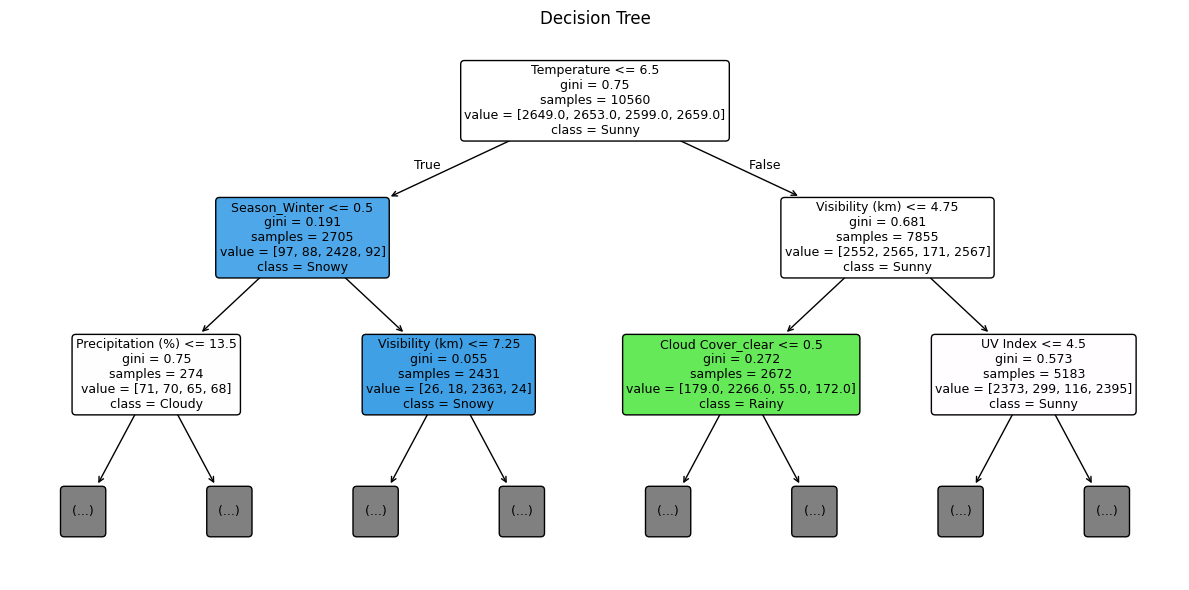

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("weather_classification_data.csv")

print(df.head())
print("\nColumns:", df.columns.tolist())
target = "Weather Type"

X = df.drop(target, axis=1)
y = df[target]

X = pd.get_dummies(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))



import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 6))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=2
)

plt.title("Decision Tree")
plt.tight_layout()
plt.show()

7.K-nearest neigbour classifier(knn)

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
data = {
    'Age': [22, 25, 47, 52, 46, 56, 23, 30, 40, 50],
    'Salary': [20000, 25000, 50000, 60000, 45000, 65000, 22000, 30000, 40000, 55000],
    'Buy': [0, 0, 1, 1, 1, 1, 0, 0, 1, 1]
}

df = pd.DataFrame(data)

X = df[['Age', 'Salary']]
y = df['Buy']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = KNeighborsClassifier(n_neighbors=3)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Predictions:", y_pred)
print("Actual:", y_test.values)
print("Accuracy:", accuracy_score(y_test, y_pred))

new_person = pd.DataFrame([[28, 28000]], columns=['Age', 'Salary'])
print("New Prediction:", model.predict(new_person))

Predictions: [1 0]
Actual: [1 0]
Accuracy: 1.0
New Prediction: [0]


8.k-mean & k-medoid clustering


   Age  Salary  Cluster
0   20      20        0
1   22      22        0
2   25      25        0
3   45      45        2
4   47      48        2
5   50      50        2
6   60      60        1
7   62      65        1


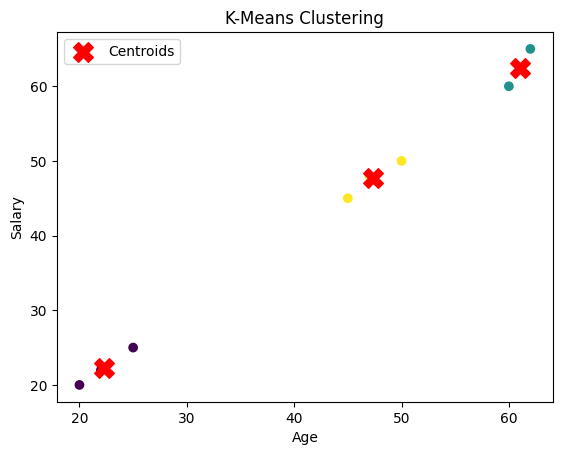

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Simple dataset
data = {
    'Age': [20, 22, 25, 45, 47, 50, 60, 62],
    'Salary': [20, 22, 25, 45, 48, 50, 60, 65]
}

df = pd.DataFrame(data)

# K-Means model
model = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = model.fit_predict(df)

print(df)

# Visualization
plt.scatter(df['Age'], df['Salary'], c=df['Cluster'], cmap='viridis')
plt.scatter(model.cluster_centers_[:, 0],
            model.cluster_centers_[:, 1],
            color='red', marker='X', s=200, label='Centroids')

plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('K-Means Clustering')
plt.legend()
plt.show()

   Age  Salary  Cluster
0   20      20        0
1   22      22        0
2   25      25        0
3   45      45        1
4   47      48        1
5   50      50        1
6   60      60        2
7   62      65        2


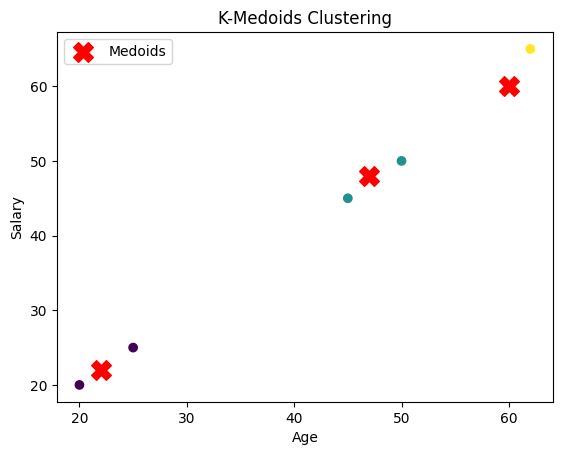

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn_extra.cluster import KMedoids

# Simple dataset
data = {
    'Age': [20, 22, 25, 45, 47, 50, 60, 62],
    'Salary': [20, 22, 25, 45, 48, 50, 60, 65]
}

df = pd.DataFrame(data)

# K-Medoids model
model = KMedoids(n_clusters=3, random_state=42)
df['Cluster'] = model.fit_predict(df)

print(df)

# Visualization
plt.scatter(df['Age'], df['Salary'], c=df['Cluster'], cmap='viridis')
plt.scatter(model.cluster_centers_[:, 0],
            model.cluster_centers_[:, 1],
            color='red', marker='X', s=200, label='Medoids')

plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('K-Medoids Clustering')
plt.legend()
plt.show()

In [ ]:
%pip install scikit-learn-extra


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 13.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154559 sha256=e9d31a2e08afe851abd8f850d50d2ce87edbaa4a9f93ae094de15b45b587e372
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra
